<a href="https://colab.research.google.com/github/mxrse218/Praktikum-Citra-Digital-5-6/blob/main/Praktikum_5_6_Pengolahan_Citra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1.a Translasi Citra
Menggeser gambar sejauh `shiftX` (horizontal) dan `shiftY` (vertikal). Bagian yang kosong diisi warna hitam.

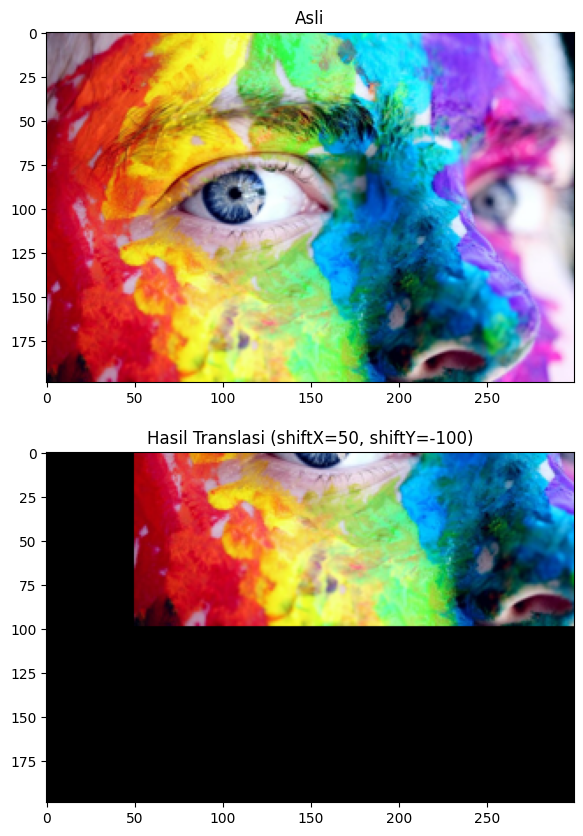

In [2]:
def Translasi(image, shiftX, shiftY):

    imgTranslasi = np.roll(image, shift=shiftY, axis=0)  # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)  # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas
    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi


# Nilai geser disesuaikan dengan ukuran gambar yang sudah diperkecil
imgResult = Translasi(image, shiftX=50, shiftY=-100)

plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(image); plt.title("Asli")
plt.subplot(2,1,2)
plt.imshow(imgResult); plt.title("Hasil Translasi (shiftX=50, shiftY=-100)")
plt.show()

## 1.b Mirroring (Horizontal & Vertikal, terpisah)
- **Horizontal**: `horizontal[y, x] = image[y, width-1-x]`
- **Vertikal**: `vertical[y, x] = image[height-1-y, x]`

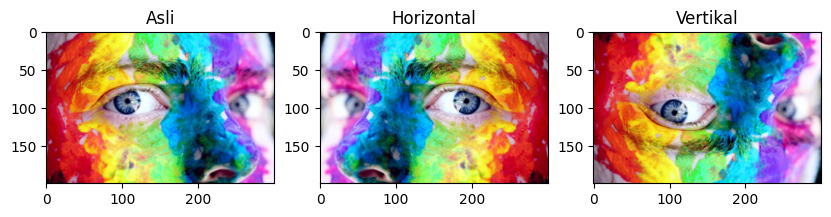

In [3]:
height, width = image.shape[:2]
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

for y in range(height):
    for x in range(width):
        vertical[y,x] = image[height - 1-y,x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(image); plt.title("Asli")

plt.subplot(1, 3, 2)
plt.imshow(horizontal); plt.title("Horizontal")

plt.subplot(1, 3, 3)
plt.imshow(vertical); plt.title("Vertikal")

plt.show()

## 1.c Rotasi Citra
Rotasi dengan pusat (pivot) di **tengah gambar**. Kanvas output dibuat sebesar diagonal gambar agar tidak terpotong.

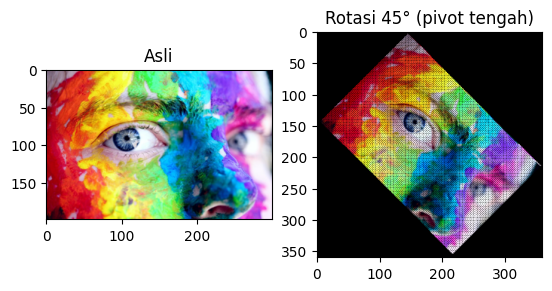

In [4]:
def rotateImage(image,degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim,max_dim,3),dtype=image.dtype)

    centerY, centerX = max_dim//2, max_dim//2

    for y in range(-height//2,height//2):
        for x in range(-width//2,width//2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <=newX <  max_dim and 0 <= newY < max_dim:
                outputImage[newY,newX] = image[y + height//2, x + width//2]
    return outputImage


rotated_image = rotateImage(image, 45)

plt.subplot(1, 2, 1)
plt.imshow(image); plt.title("Asli")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image); plt.title("Rotasi 45° (pivot tengah)")

plt.show()

## 1.d Zooming
Fungsi `zoomPlus` memetakan setiap piksel hasil ke piksel asli dengan `ori = piksel * factor` (nearest neighbor).

> **Catatan:** ukuran hasil = ukuran asli ÷ `factor`. Jadi `factor < 1` (mis. 0,5) **memperbesar** gambar (zoom in), sedangkan `factor > 1` memperkecil. Pada demo ini dipakai `skala = 0.5` agar terlihat efek zoom in.

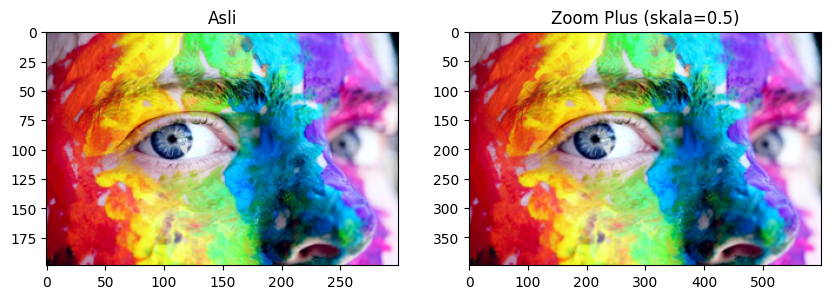

In [11]:
def zoomPlus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)
    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):

            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


skala = 0.5   # <1 = zoom in (diperbesar 2x)

imgZoom = zoomPlus(image, skala)
img.imwrite("z.jpg", imgZoom)   # tersimpan di folder Colab (panel Files di kiri)

plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.imshow(image); plt.title("Asli")

plt.subplot(1, 2, 2)
plt.imshow(imgZoom); plt.title(f"Zoom Plus (skala={skala})")
plt.show()

---
# 2. Modifikasi Kode Program

## 2.a Mirroring Vertikal dan Horizontal Bersamaan
Kedua pencerminan dilakukan sekaligus dalam satu perulangan:
`both[y, x] = image[height-1-y, width-1-x]` (hasilnya sama dengan rotasi 180°).

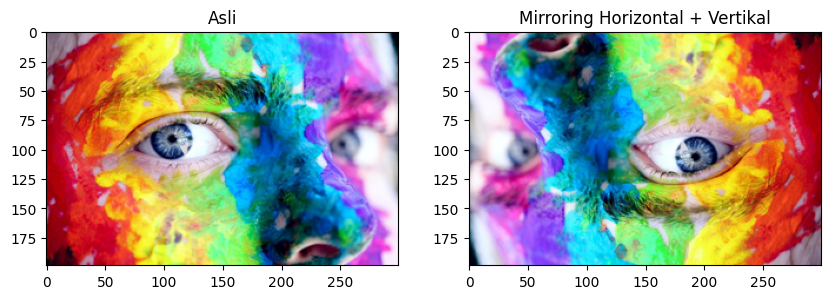

In [6]:
height, width = image.shape[:2]
both = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        both[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image); plt.title("Asli")

plt.subplot(1, 2, 2)
plt.imshow(both); plt.title("Mirroring Horizontal + Vertikal")

plt.show()

## 2.b Rotasi dengan Pivot di Titik (0,0) Pojok Kiri Atas
Koordinat piksel langsung dirotasi terhadap titik (0,0) tanpa menggeser ke tengah:

$$x' = x\cos\theta - y\sin\theta \qquad y' = x\sin\theta + y\cos\theta$$

Karena hasil rotasi bisa bernilai negatif, kanvas output diberi *offset* agar seluruh gambar terlihat. Titik pivot (0,0) ditandai dengan titik merah. Dipakai **pemetaan balik** (*inverse mapping*) agar tidak muncul lubang hitam pada hasil.

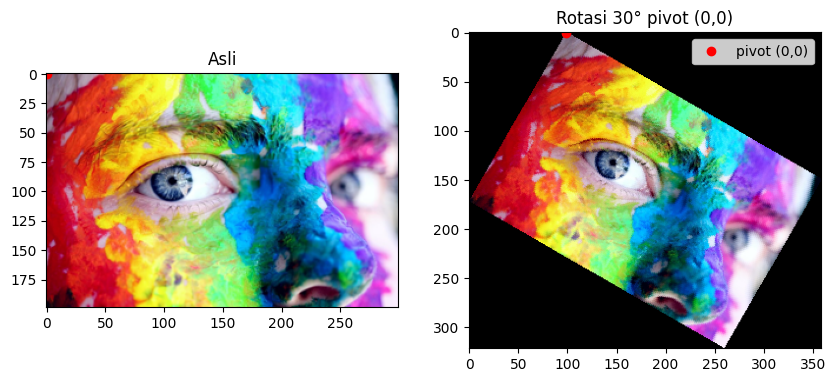

In [7]:
def rotateImagePivot00(image, degree):
    rad = np.radians(degree)
    cos_deg, sin_deg = np.cos(rad), np.sin(rad)

    height, width = image.shape[:2]

    # Rotasi keempat sudut gambar terhadap (0,0) untuk menentukan ukuran kanvas
    sudut = [(0, 0), (width - 1, 0), (0, height - 1), (width - 1, height - 1)]
    xs = [cos_deg * x - sin_deg * y for x, y in sudut]
    ys = [sin_deg * x + cos_deg * y for x, y in sudut]

    min_x, max_x = int(np.floor(min(xs))), int(np.ceil(max(xs)))
    min_y, max_y = int(np.floor(min(ys))), int(np.ceil(max(ys)))

    out_w, out_h = max_x - min_x + 1, max_y - min_y + 1
    output = np.zeros((out_h, out_w, 3), dtype=image.dtype)

    # Untuk setiap piksel output, cari piksel asalnya (rotasi balik terhadap (0,0))
    for yo in range(out_h):
        for xo in range(out_w):
            X = xo + min_x          # koordinat sebenarnya (pivot = 0,0)
            Y = yo + min_y
            x_src = int(round( cos_deg * X + sin_deg * Y))
            y_src = int(round(-sin_deg * X + cos_deg * Y))
            if 0 <= x_src < width and 0 <= y_src < height:
                output[yo, xo] = image[y_src, x_src]

    pivot = (-min_x, -min_y)   # posisi titik (0,0) pada kanvas output
    return output, pivot


rotated_pivot, pivot = rotateImagePivot00(image, 30)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image); plt.title("Asli")
plt.plot(0, 0, 'ro')

plt.subplot(1, 2, 2)
plt.imshow(rotated_pivot); plt.title("Rotasi 30° pivot (0,0)")
plt.plot(pivot[0], pivot[1], 'ro', label="pivot (0,0)")
plt.legend()
plt.show()

## 2.c Zoom Minus (Memperkecil Gambar)
`zoomMinus` memperkecil gambar sebesar `factor` kali (`factor > 1`). Ukuran baru = ukuran asli ÷ `factor`, dan tiap piksel hasil mengambil piksel asli pada posisi `y * factor`, `x * factor`.

Ukuran asli : (199, 300)
Ukuran hasil: (99, 150)


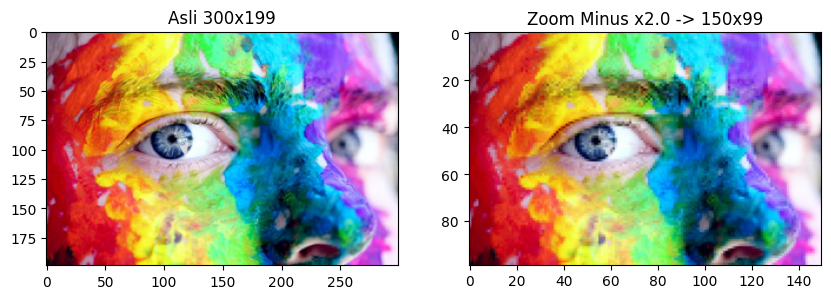

In [8]:
def zoomMinus(image, factor):
    if factor <= 1:
        raise ValueError("Untuk memperkecil, factor harus > 1")

    height, width = image.shape[:2]
    new_height = max(1, int(height / factor))
    new_width = max(1, int(width / factor))
    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = min(int(y * factor), height - 1)
            ori_x = min(int(x * factor), width - 1)
            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom


skala_minus = 2.0
imgMinus = zoomMinus(image, skala_minus)
print("Ukuran asli :", image.shape[:2])
print("Ukuran hasil:", imgMinus.shape[:2])

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image); plt.title(f"Asli {image.shape[1]}x{image.shape[0]}")

plt.subplot(1, 2, 2)
plt.imshow(imgMinus); plt.title(f"Zoom Minus x{skala_minus} -> {imgMinus.shape[1]}x{imgMinus.shape[0]}")
plt.show()